# Fundamentals of Data Science: Case Study 2 and Case Study 5

## Importing Libraries

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.prop_cycle": cycler(color=["black", "dimgray", "gray", "darkgray"]),
    "axes.edgecolor": "black",
    "axes.labelcolor": "black",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "text.color": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "grid.color": "lightgray",
})

strength_map = LinearSegmentedColormap.from_list("strength", ["#8c8c8c", "#ffffff", "#8c8c8c"])

## Case Study 2: Clustering Analysis

### Loading the Dataset

In [2]:
airline = pd.read_excel("data/EastWestAirlines.xlsx", sheet_name="data")
print(airline.shape)
print(airline.head())
airline.info()

(3999, 12)
   ID#  Balance  Qual_miles  cc1_miles  cc2_miles  cc3_miles  Bonus_miles  Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll  Award?
0    1    28143           0          1          1          1          174            1                  0                0               7000       0
1    2    19244           0          1          1          1          215            2                  0                0               6968       0
2    3    41354           0          1          1          1         4123            4                  0                0               7034       0
3    4    14776           0          1          1          1          500            1                  0                0               6952       0
4    5    97752           0          4          1          1        43300           26               2077                4               6935       1
<class 'pandas.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 col

### Missing Values and Duplicates

In [3]:
airline = airline.drop(columns="ID#")
print(airline.isna().sum())
print("Duplicate rows:", airline.duplicated().sum())
airline = airline.drop_duplicates().reset_index(drop=True)
print(airline.shape)

Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64
Duplicate rows: 1
(3998, 11)


### Summary Statistics

In [4]:
print(airline.describe().T.round(2))

                    count      mean        std  min       25%      50%       75%        max
Balance            3998.0  73619.49  100781.73  0.0  18534.25  43138.0  92405.00  1704838.0
Qual_miles         3998.0    144.15     773.76  0.0      0.00      0.0      0.00    11148.0
cc1_miles          3998.0      2.06       1.38  1.0      1.00      1.0      3.00        5.0
cc2_miles          3998.0      1.01       0.15  1.0      1.00      1.0      1.00        3.0
cc3_miles          3998.0      1.01       0.20  1.0      1.00      1.0      1.00        5.0
Bonus_miles        3998.0  17149.13   24152.47  0.0   1250.00   7183.0  23810.75   263685.0
Bonus_trans        3998.0     11.60       9.60  0.0      3.00     12.0     17.00       86.0
Flight_miles_12mo  3998.0    460.17    1400.37  0.0      0.00      0.0    313.50    30817.0
Flight_trans_12    3998.0      1.37       3.79  0.0      0.00      0.0      1.00       53.0
Days_since_enroll  3998.0   4119.19    2065.01  2.0   2331.25   4097.5   5790.75

### Exploratory Data Analysis

#### Distribution of Key Variables

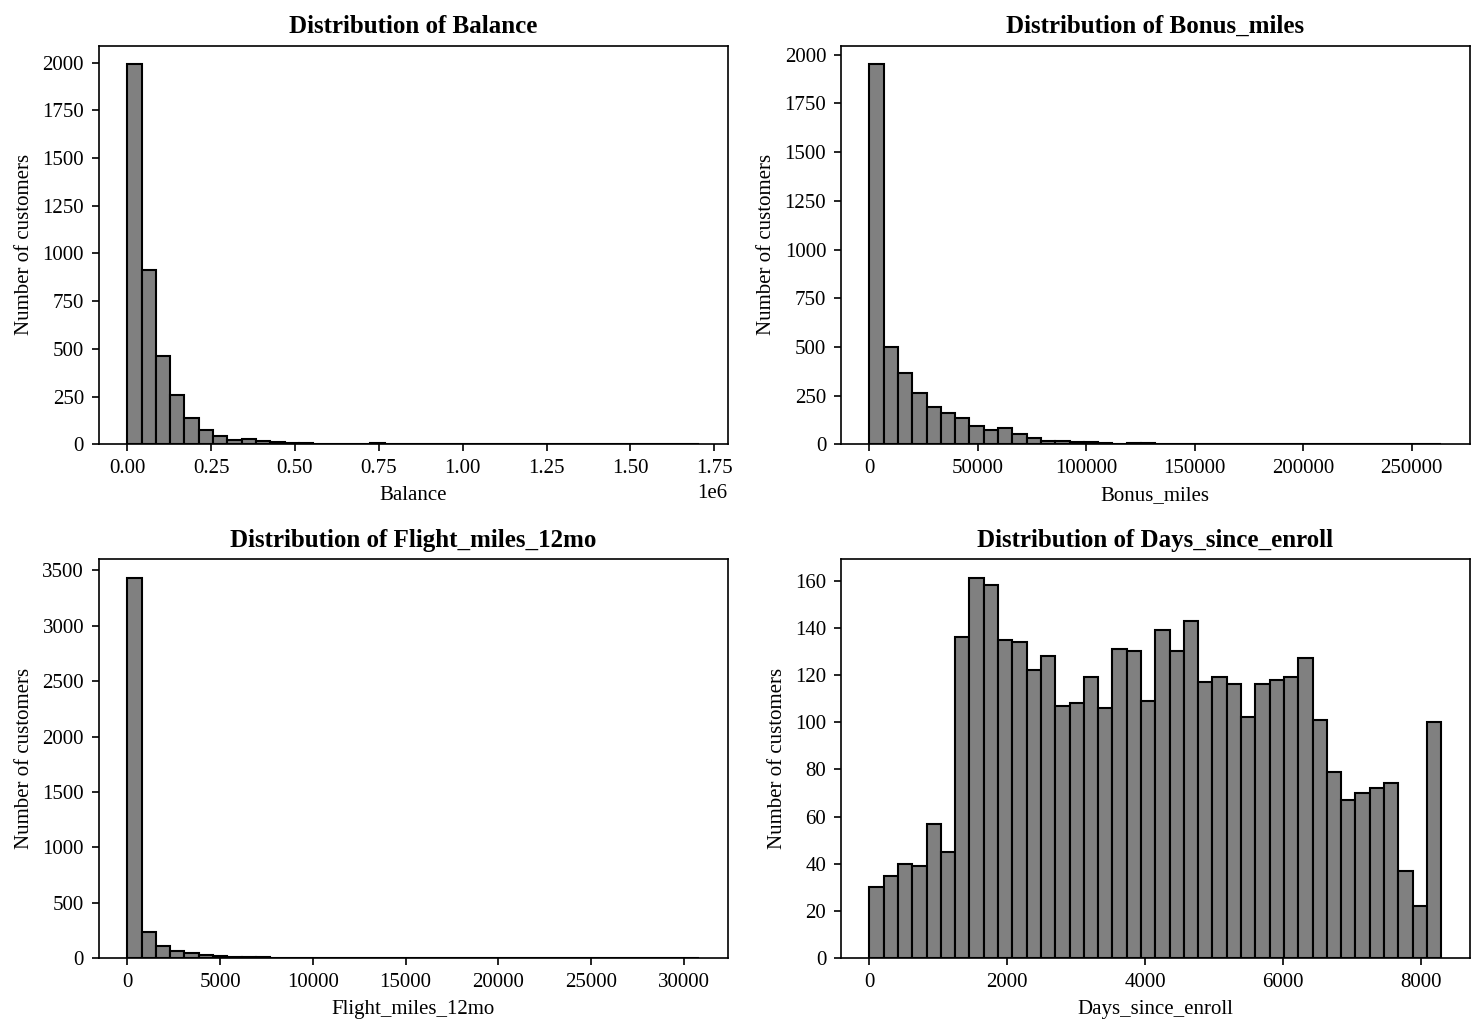

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.ravel(), ["Balance", "Bonus_miles", "Flight_miles_12mo", "Days_since_enroll"]):
    ax.hist(airline[col], bins=40, color="gray", edgecolor="black")
    ax.set_title("Distribution of " + col)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

#### Box Plots Before Outlier Removal

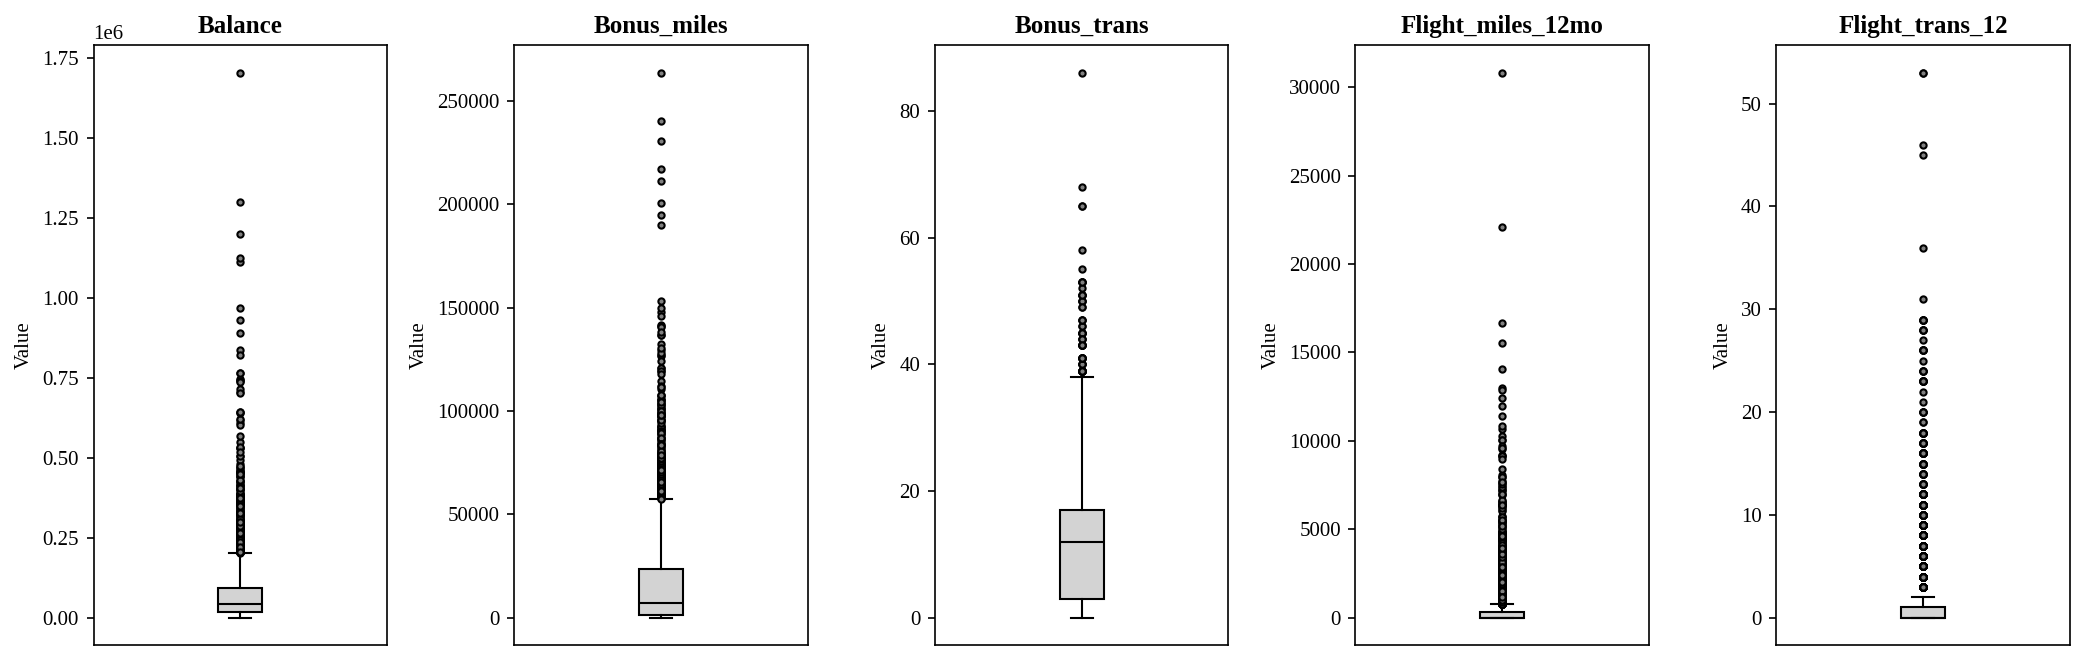

In [6]:
numeric_cols = ["Balance", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12"]
fig, axes = plt.subplots(1, 5, figsize=(14, 4.5))
for ax, col in zip(axes, numeric_cols):
    ax.boxplot(airline[col], patch_artist=True,
               boxprops=dict(facecolor="lightgray", edgecolor="black"),
               medianprops=dict(color="black"),
               flierprops=dict(marker="o", markerfacecolor="gray", markeredgecolor="black", markersize=3))
    ax.set_title(col)
    ax.set_xticks([])
    ax.set_ylabel("Value")
plt.tight_layout()
plt.show()

#### Credit Card Mile Bins and Award Status

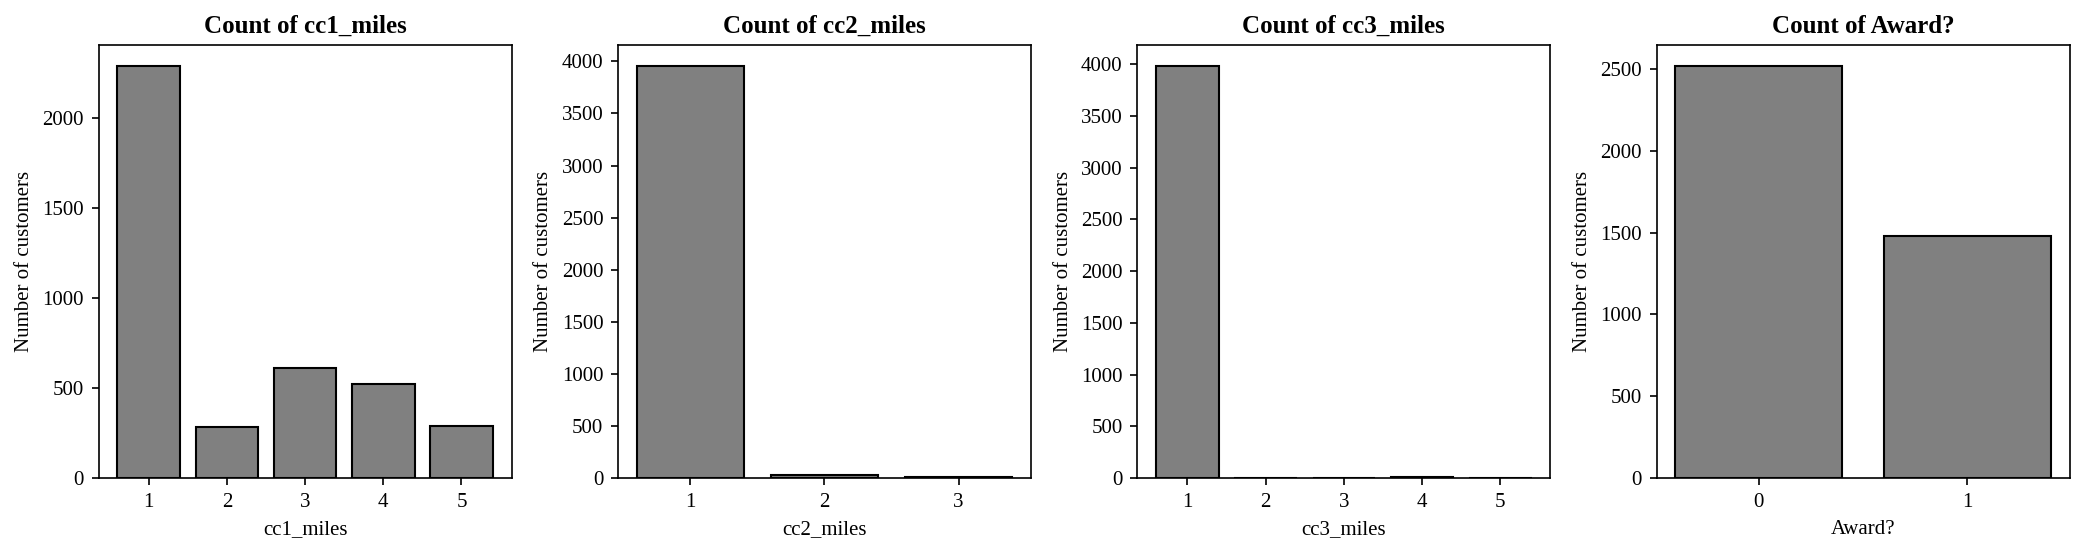

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, col in zip(axes, ["cc1_miles", "cc2_miles", "cc3_miles", "Award?"]):
    counts = airline[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color="gray", edgecolor="black")
    ax.set_title("Count of " + col)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

#### Relationships Between Variables

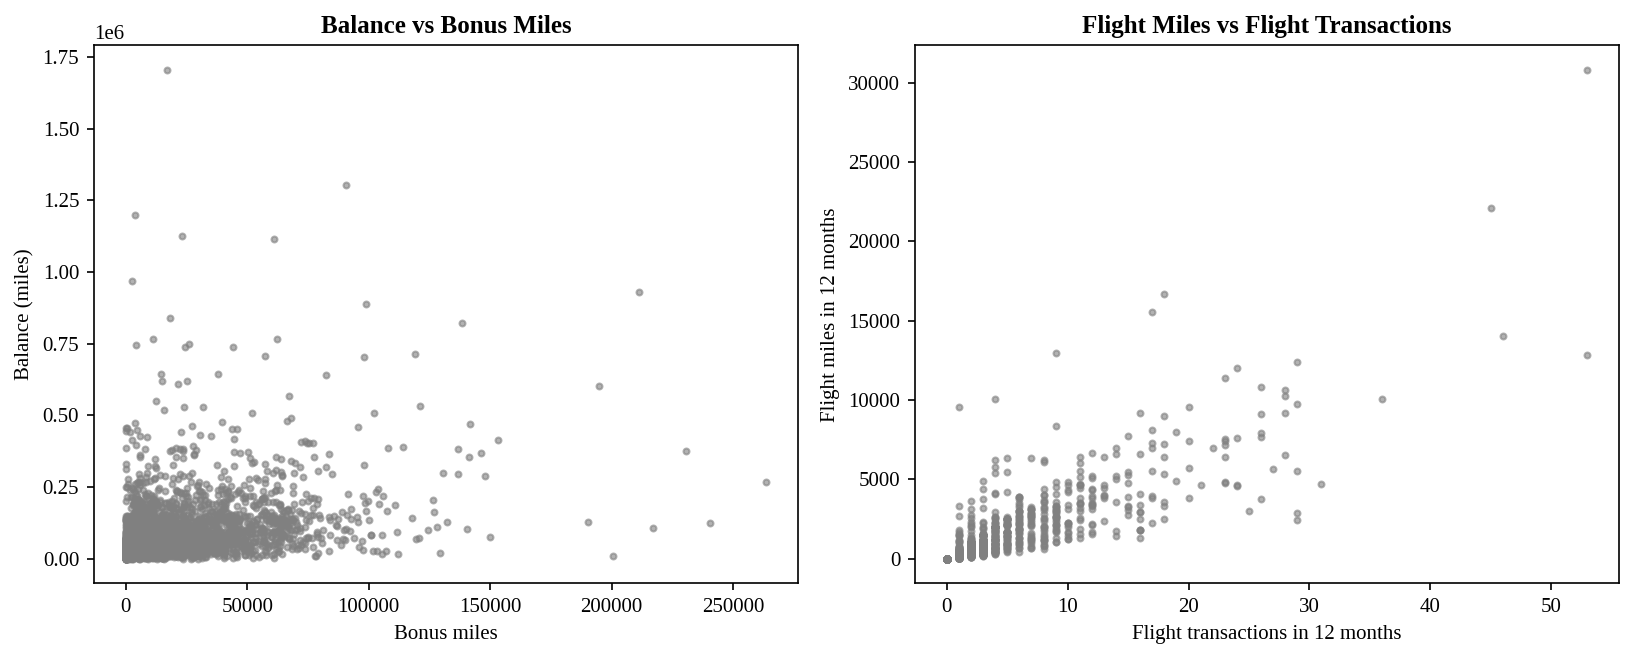

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(airline["Bonus_miles"], airline["Balance"], s=8, color="gray", alpha=0.6)
axes[0].set_title("Balance vs Bonus Miles")
axes[0].set_xlabel("Bonus miles")
axes[0].set_ylabel("Balance (miles)")
axes[1].scatter(airline["Flight_trans_12"], airline["Flight_miles_12mo"], s=8, color="gray", alpha=0.6)
axes[1].set_title("Flight Miles vs Flight Transactions")
axes[1].set_xlabel("Flight transactions in 12 months")
axes[1].set_ylabel("Flight miles in 12 months")
plt.tight_layout()
plt.show()

#### Correlation Heatmap

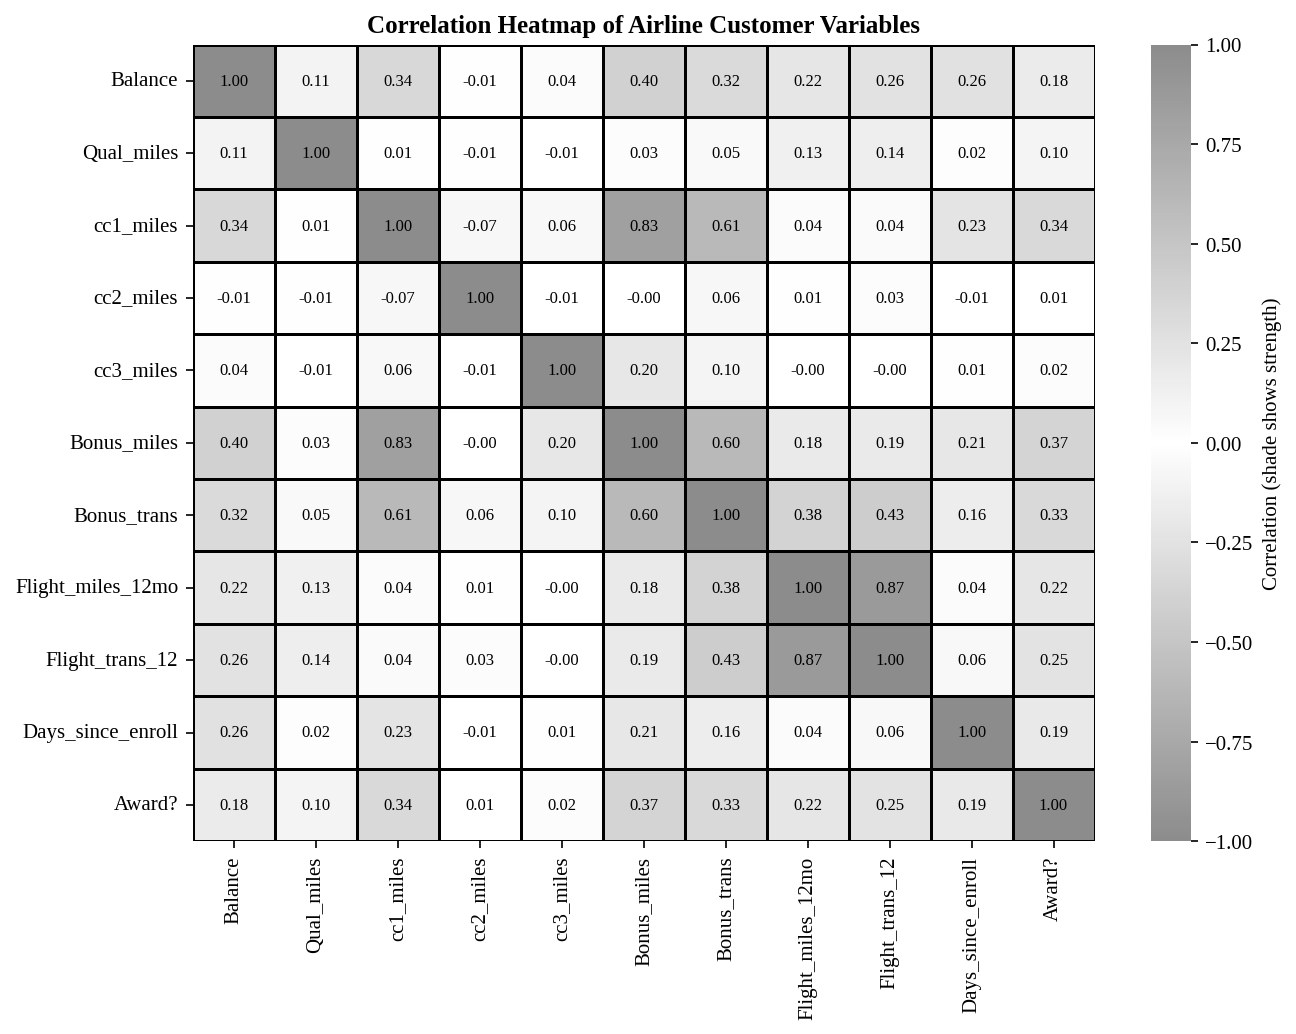

In [9]:
corr_air = airline.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_air, annot=True, fmt=".2f", cmap=strength_map, vmin=-1, vmax=1,
            linewidths=0.5, linecolor="black", cbar_kws={"label": "Correlation (shade shows strength)"},
            annot_kws={"color": "black", "size": 8})
plt.title("Correlation Heatmap of Airline Customer Variables")
plt.tight_layout()
plt.show()

### Outlier Removal

In [10]:
outlier_cols = ["Balance", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12"]
z_scores = (airline[outlier_cols] - airline[outlier_cols].mean()) / airline[outlier_cols].std()
keep = (z_scores.abs() <= 3).all(axis=1)
print("Rows before:", len(airline))
print("Rows removed:", (~keep).sum())
airline_clean = airline[keep].reset_index(drop=True)
print("Rows after:", len(airline_clean))

Rows before: 3998
Rows removed: 249
Rows after: 3749


### Feature Scaling

In [11]:
scaler = StandardScaler()
X_air = scaler.fit_transform(airline_clean)
print(pd.DataFrame(X_air, columns=airline_clean.columns).describe().loc[["mean", "std"]].round(2))

      Balance  Qual_miles  cc1_miles  cc2_miles  cc3_miles  Bonus_miles  Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll  Award?
mean      0.0         0.0        0.0        0.0        0.0          0.0         -0.0               -0.0              0.0                0.0    -0.0
std       1.0         1.0        1.0        1.0        1.0          1.0          1.0                1.0              1.0                1.0     1.0


### K-Means Clustering

#### Elbow Curve and Silhouette Scores

    k  inertia  silhouette
0   2  32827.3       0.304
1   3  28160.0       0.307
2   4  24894.6       0.319
3   5  22405.3       0.328
4   6  19879.6       0.206
5   7  17237.7       0.273
6   8  15663.5       0.274
7   9  14473.6       0.237
8  10  13582.4       0.245


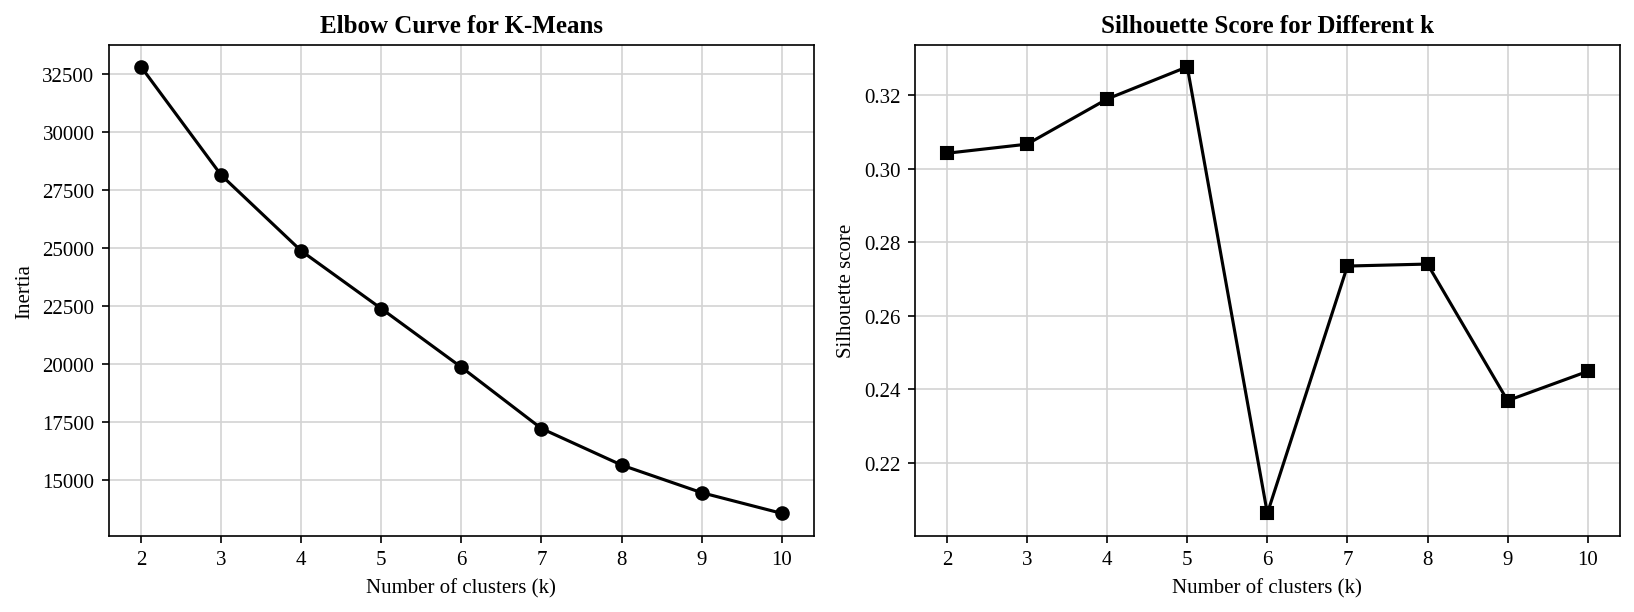

In [12]:
k_values = list(range(2, 11))
inertias = []
sil_scores = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_air)
    inertias.append(model.inertia_)
    sil_scores.append(silhouette_score(X_air, model.labels_))
print(pd.DataFrame({"k": k_values, "inertia": np.round(inertias, 1), "silhouette": np.round(sil_scores, 3)}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(k_values, inertias, marker="o", color="black")
axes[0].set_title("Elbow Curve for K-Means")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True)
axes[1].plot(k_values, sil_scores, marker="s", color="black")
axes[1].set_title("Silhouette Score for Different k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].grid(True)
plt.tight_layout()
plt.show()

#### Final K-Means Model

In [13]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_air)
labels_km = kmeans.labels_
sil_km = silhouette_score(X_air, labels_km)
print("K-Means silhouette score:", round(sil_km, 3))
print(pd.Series(labels_km).value_counts().sort_index())

K-Means silhouette score: 0.319
0    2229
1    1231
2     251
3      38
Name: count, dtype: int64


### Hierarchical Clustering

#### Dendrogram

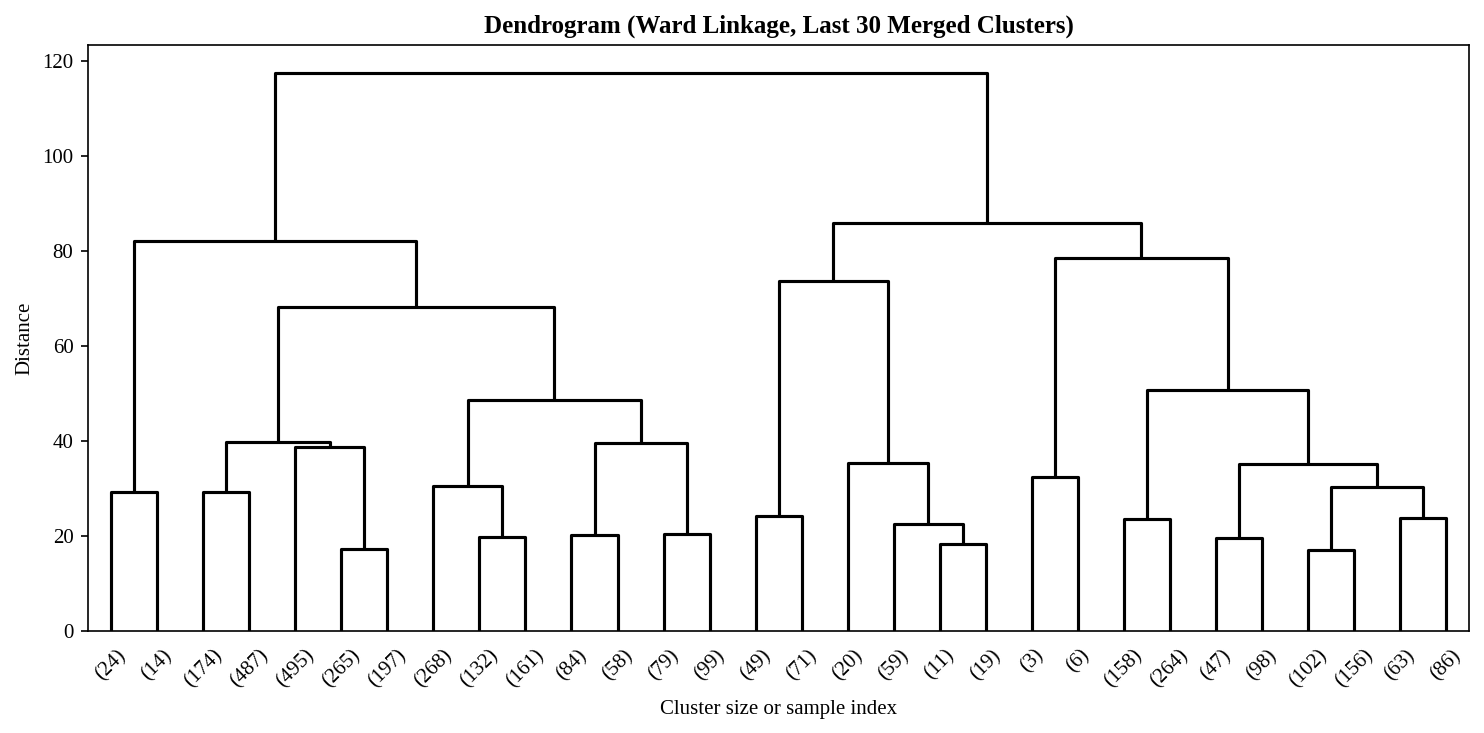

In [14]:
Z = linkage(X_air, method="ward")
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=0, above_threshold_color="black")
plt.title("Dendrogram (Ward Linkage, Last 30 Merged Clusters)")
plt.xlabel("Cluster size or sample index")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

#### Comparing Linkage Methods

In [15]:
rows = []
for method in ["ward", "complete", "average", "single"]:
    for k in [3, 4, 5]:
        lab = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X_air)
        sizes = np.bincount(lab)
        rows.append([method, k, round(silhouette_score(X_air, lab), 3), int(sizes.max()), int(sizes.min())])
linkage_table = pd.DataFrame(rows, columns=["linkage", "clusters", "silhouette", "largest_cluster", "smallest_cluster"])
print(linkage_table)

     linkage  clusters  silhouette  largest_cluster  smallest_cluster
0       ward         3       0.271             2537               229
1       ward         4       0.287             2499                38
2       ward         5       0.282             2499                 9
3   complete         3       0.726             3740                 3
4   complete         4       0.631             3702                 3
5   complete         5       0.630             3680                 3
6    average         3       0.789             3743                 3
7    average         4       0.631             3705                 3
8    average         5       0.616             3702                 3
9     single         3       0.820             3743                 1
10    single         4       0.789             3743                 1
11    single         5       0.607             3740                 1


#### Final Hierarchical Model

In [16]:
hier = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(X_air)
labels_hc = hier.labels_
sil_hc = silhouette_score(X_air, labels_hc)
print("Hierarchical (Ward) silhouette score:", round(sil_hc, 3))
print(pd.Series(labels_hc).value_counts().sort_index())

Hierarchical (Ward) silhouette score: 0.287
0     983
1    2499
2     229
3      38
Name: count, dtype: int64


### DBSCAN Clustering

#### K-Distance Plot

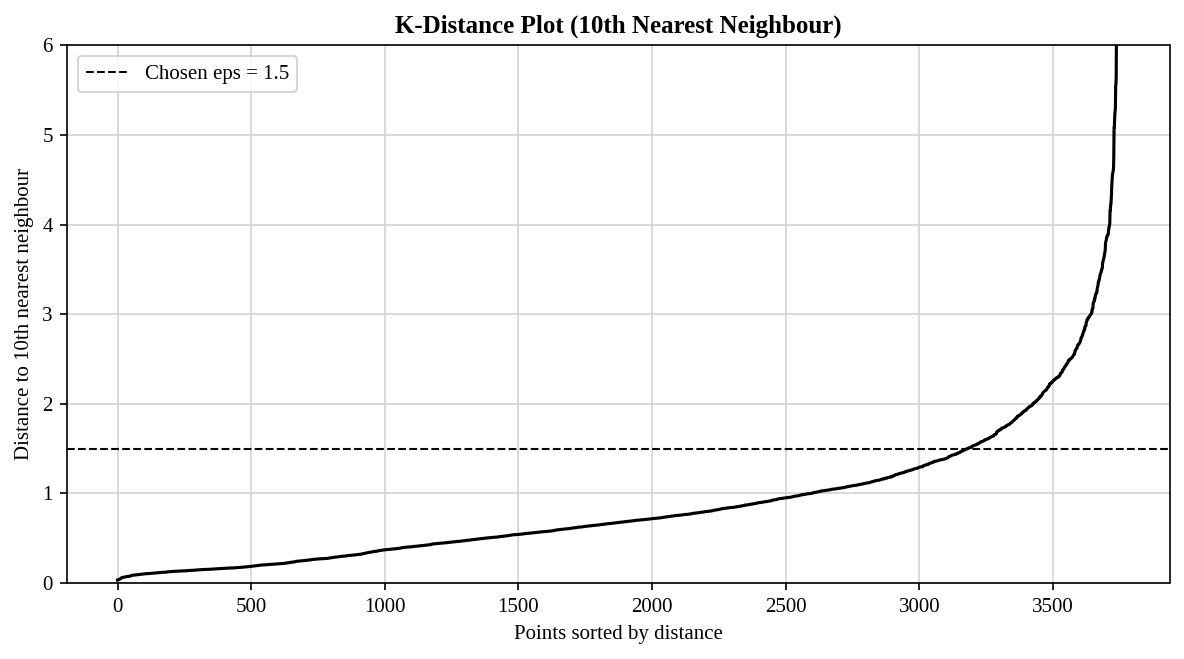

In [17]:
neighbors = NearestNeighbors(n_neighbors=10).fit(X_air)
distances, _ = neighbors.kneighbors(X_air)
k_dist = np.sort(distances[:, -1])
plt.figure(figsize=(8, 4.5))
plt.plot(k_dist, color="black")
plt.axhline(1.5, color="black", linestyle="--", linewidth=1, label="Chosen eps = 1.5")
plt.ylim(0, 6)
plt.legend()
plt.title("K-Distance Plot (10th Nearest Neighbour)")
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to 10th nearest neighbour")
plt.grid(True)
plt.tight_layout()
plt.show()

#### Trying Different Parameters

In [18]:
rows = []
for eps in [0.8, 1.0, 1.2, 1.5, 2.0]:
    for min_pts in [5, 10, 20]:
        lab = DBSCAN(eps=eps, min_samples=min_pts).fit_predict(X_air)
        n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
        noise = int((lab == -1).sum())
        sil = silhouette_score(X_air[lab != -1], lab[lab != -1]) if n_clusters > 1 else np.nan
        rows.append([eps, min_pts, n_clusters, noise, round(sil, 3)])
dbscan_table = pd.DataFrame(rows, columns=["eps", "minPts", "clusters", "noise_points", "silhouette"])
print(dbscan_table)

    eps  minPts  clusters  noise_points  silhouette
0   0.8       5        14           935       0.154
1   0.8      10         4          1186       0.273
2   0.8      20         4          1436       0.277
3   1.0       5         7           637       0.259
4   1.0      10         2           821       0.302
5   1.0      20         3          1014       0.277
6   1.2       5         9           470       0.217
7   1.2      10         3           582       0.285
8   1.2      20         2           714       0.296
9   1.5       5         6           278       0.214
10  1.5      10         4           370       0.255
11  1.5      20         2           469       0.277
12  2.0       5         5           145       0.257
13  2.0      10         3           193       0.259
14  2.0      20         2           281       0.263


#### Final DBSCAN Model

In [19]:
dbscan = DBSCAN(eps=1.5, min_samples=10).fit(X_air)
labels_db = dbscan.labels_
mask_db = labels_db != -1
sil_db = silhouette_score(X_air[mask_db], labels_db[mask_db])
print("DBSCAN silhouette score (without noise):", round(sil_db, 3))
print(pd.Series(labels_db).value_counts().sort_index())

DBSCAN silhouette score (without noise): 0.255
-1     370
 0    2291
 1    1065
 2      13
 3      10
Name: count, dtype: int64


### Visualising the Clusters with PCA

Variance explained: [0.288 0.166]


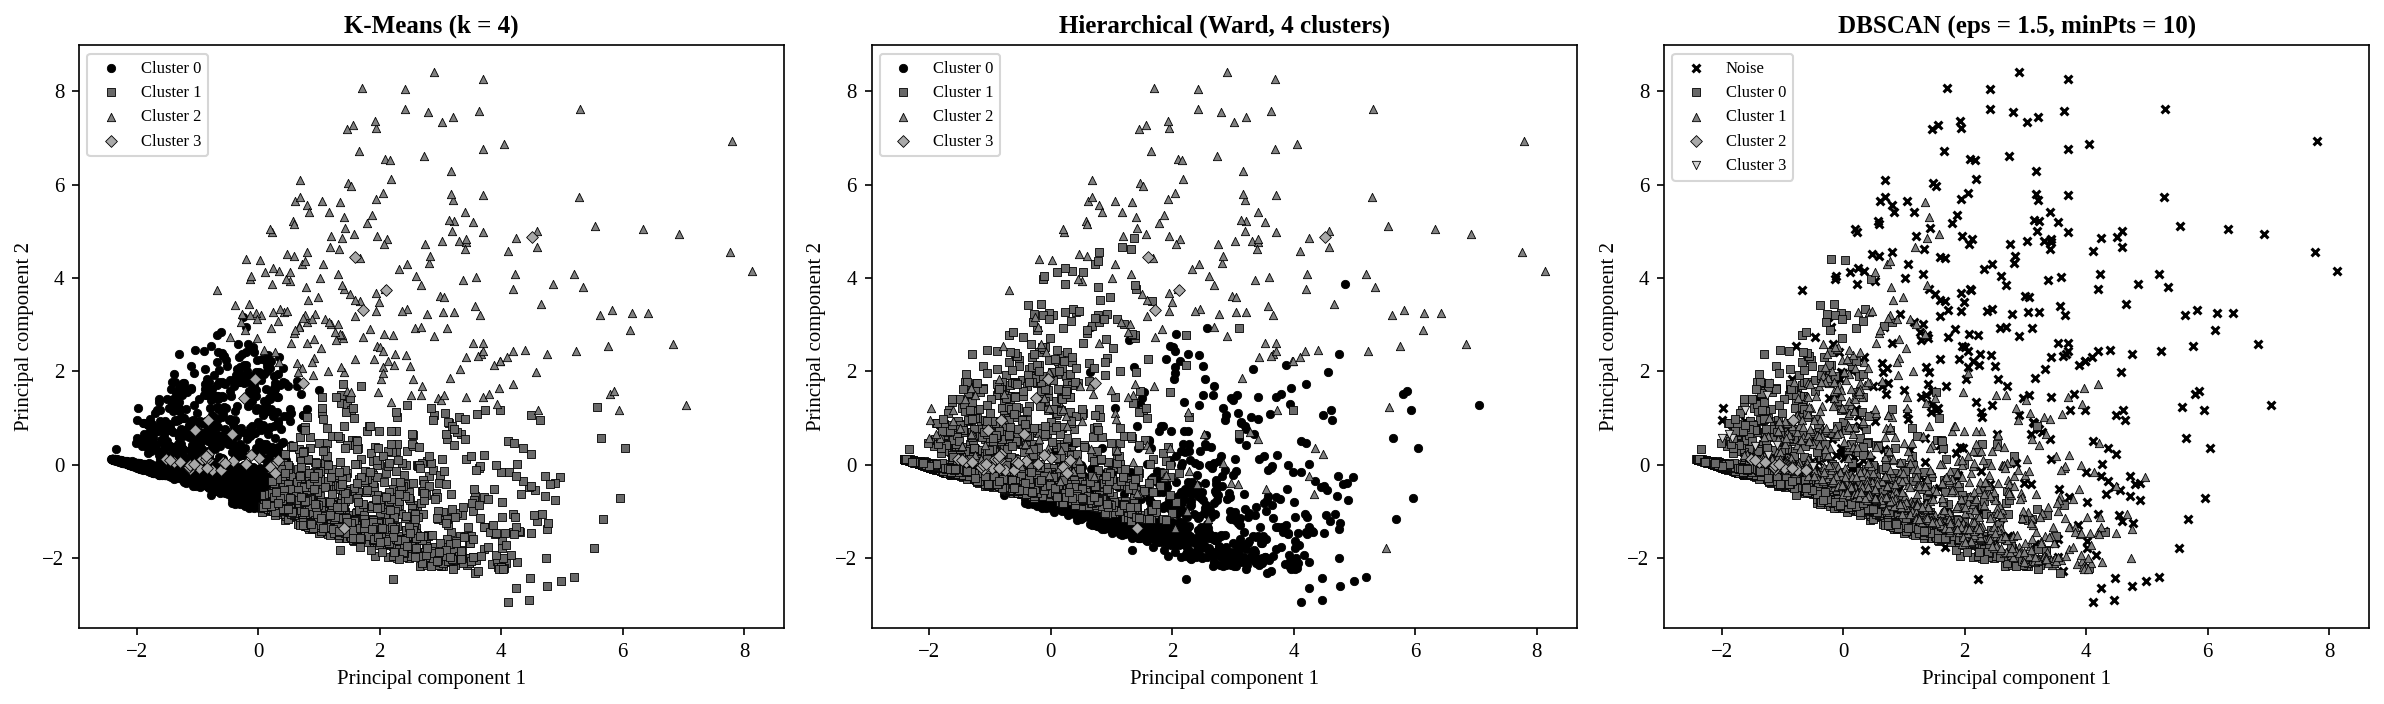

In [20]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_air)
print("Variance explained:", np.round(pca.explained_variance_ratio_, 3))

shades = ["black", "dimgray", "gray", "darkgray", "lightgray"]
markers = ["o", "s", "^", "D", "v"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, labs, title in zip(axes, [labels_km, labels_hc, labels_db],
                           ["K-Means (k = 4)", "Hierarchical (Ward, 4 clusters)", "DBSCAN (eps = 1.5, minPts = 10)"]):
    for i, c in enumerate(sorted(set(labs))):
        pts = X_pca[labs == c]
        if c == -1:
            ax.scatter(pts[:, 0], pts[:, 1], marker="x", color="black", s=14, label="Noise")
        else:
            ax.scatter(pts[:, 0], pts[:, 1], marker=markers[i % 5], facecolor=shades[i % 5],
                       edgecolor="black", linewidth=0.4, s=16, label="Cluster " + str(c))
    ax.set_title(title)
    ax.set_xlabel("Principal component 1")
    ax.set_ylabel("Principal component 2")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Cluster Profiles

In [21]:
profile_df = airline_clean.copy()
profile_df["KMeans"] = labels_km
profile_df["Hierarchical"] = labels_hc
profile_df["DBSCAN"] = labels_db

km_profile = profile_df.groupby("KMeans").mean().drop(columns=["Hierarchical", "DBSCAN"]).round(1)
km_profile.insert(0, "Customers", profile_df["KMeans"].value_counts().sort_index())
print(km_profile.T)

KMeans                   0        1         2        3
Customers           2229.0   1231.0     251.0     38.0
Balance            38195.6  95736.7  101095.8  42433.4
Qual_miles            96.8    122.9     489.3      0.0
cc1_miles              1.1      3.6       2.0      1.1
cc2_miles              1.0      1.0       1.0      2.4
cc3_miles              1.0      1.0       1.0      1.0
Bonus_miles         3648.0  33232.0   19091.5  14358.1
Bonus_trans            6.1     17.4      16.1     14.9
Flight_miles_12mo    101.5    154.2    2262.5    285.3
Flight_trans_12        0.4      0.5       6.4      1.1
Days_since_enroll   3654.7   4716.7    4399.7   3916.6
Award?                 0.2      0.6       0.6      0.3


In [22]:
hc_profile = profile_df.groupby("Hierarchical").mean().drop(columns=["KMeans", "DBSCAN"]).round(1)
hc_profile.insert(0, "Customers", profile_df["Hierarchical"].value_counts().sort_index())
print(hc_profile.T)

Hierarchical             0        1         2        3
Customers            983.0   2499.0     229.0     38.0
Balance            97439.0  43681.2  102284.3  42433.4
Qual_miles            15.3     17.8    1879.8      0.0
cc1_miles              3.8      1.3       2.1      1.1
cc2_miles              1.0      1.0       1.0      2.4
cc3_miles              1.0      1.0       1.0      1.0
Bonus_miles        37156.9   5059.7   20360.3  14358.1
Bonus_trans           17.5      7.4      15.2     14.9
Flight_miles_12mo    220.6    147.5    1739.9    285.3
Flight_trans_12        0.7      0.5       5.0      1.1
Days_since_enroll   4573.4   3866.6    3924.1   3916.6
Award?                 0.4      0.3       0.6      0.3


In [23]:
db_profile = profile_df.groupby("DBSCAN").mean().drop(columns=["KMeans", "Hierarchical"]).round(1)
db_profile.insert(0, "Customers", profile_df["DBSCAN"].value_counts().sort_index())
print(db_profile.T)

DBSCAN                   -1        0        1        2        3
Customers             370.0   2291.0   1065.0     13.0     10.0
Balance            120759.3  53029.0  59239.9  34806.5  26392.1
Qual_miles           1159.5      8.2     16.3      0.0   2467.4
cc1_miles               2.4      1.7      2.6      1.0      1.1
cc2_miles               1.1      1.0      1.0      2.0      1.0
cc3_miles               1.1      1.0      1.0      1.0      1.0
Bonus_miles         25927.8   9046.3  22460.8   8389.8   2938.8
Bonus_trans            17.5      8.4     12.8     12.0      5.2
Flight_miles_12mo    1426.0     96.4    230.7     19.2     40.0
Flight_trans_12         4.1      0.3      0.7      0.2      0.3
Days_since_enroll    4459.9   3801.3   4491.8   3186.2   2170.3
Award?                  0.6      0.0      1.0      0.0      0.0


#### K-Means Cluster Comparison Chart

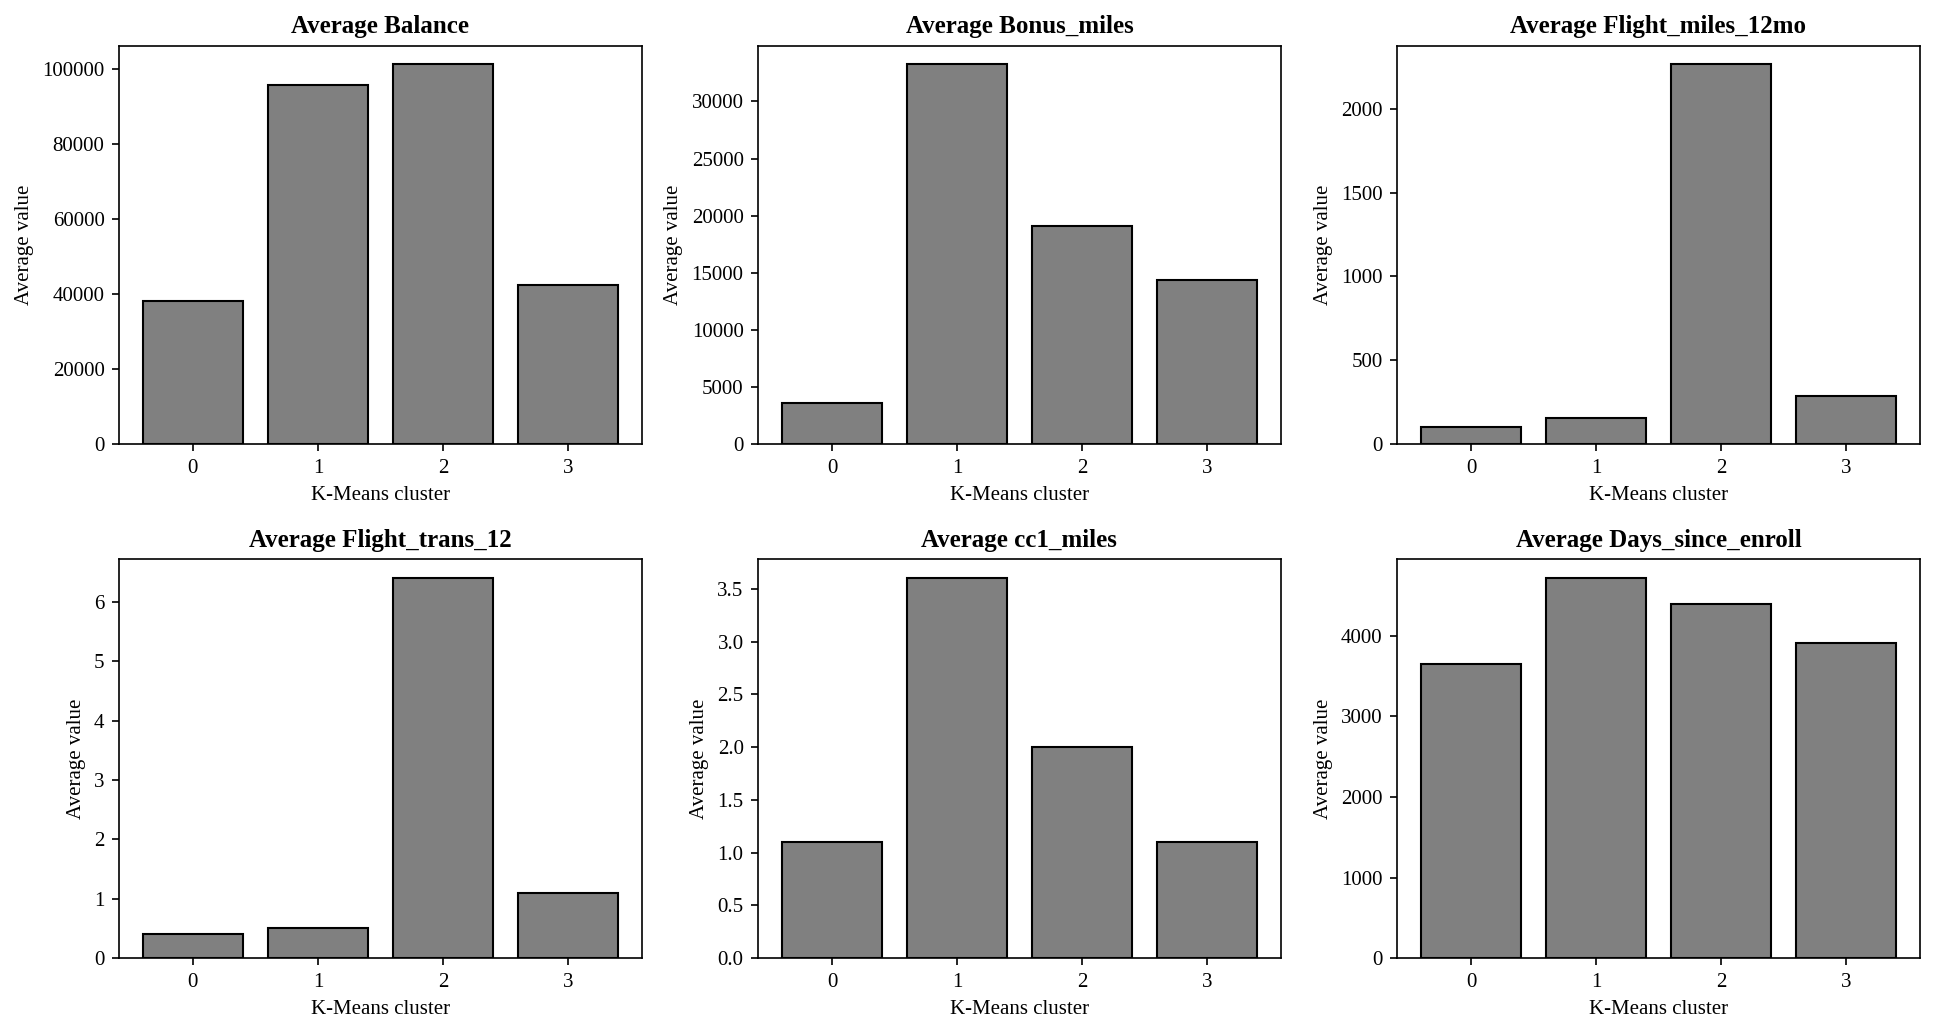

In [24]:
features = ["Balance", "Bonus_miles", "Flight_miles_12mo", "Flight_trans_12", "cc1_miles", "Days_since_enroll"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), features):
    ax.bar(km_profile.index.astype(str), km_profile[col], color="gray", edgecolor="black")
    ax.set_title("Average " + col)
    ax.set_xlabel("K-Means cluster")
    ax.set_ylabel("Average value")
plt.tight_layout()
plt.show()

### Evaluation Summary

In [25]:
summary = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical (Ward)", "DBSCAN"],
    "Clusters": [4, 4, len(set(labels_db)) - 1],
    "Noise points": [0, 0, int((labels_db == -1).sum())],
    "Silhouette score": [round(sil_km, 3), round(sil_hc, 3), round(sil_db, 3)],
})
print(summary)

             Algorithm  Clusters  Noise points  Silhouette score
0              K-Means         4             0             0.319
1  Hierarchical (Ward)         4             0             0.287
2               DBSCAN         4           370             0.255


## Case Study 5: Wine Quality Assessment

### Loading the Datasets

In [26]:
red = pd.read_csv("data/winequality-red.csv", sep=";")
white = pd.read_csv("data/winequality-white.csv", sep=";")
print("Red wine:", red.shape)
print("White wine:", white.shape)
wine = pd.concat([red, white], ignore_index=True)
print("Combined:", wine.shape)
print(wine.head())
wine.info()
print(wine.isna().sum().sum())
print("Duplicate rows:", wine.duplicated().sum())

Red wine: (1599, 12)
White wine: (4898, 12)
Combined: (6497, 12)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  alcohol  quality
0            7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978  3.51       0.56      9.4        5
1            7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968  3.20       0.68      9.8        5
2            7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970  3.26       0.65      9.8        5
3           11.2              0.28         0.56             1.9      0.075                 17.0                  60.0   0.9980  3.16       0.58      9.8        6
4            7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.997

### Task 1: Statistical Analysis

#### Descriptive Statistics

In [27]:
selected = ["alcohol", "volatile acidity", "residual sugar"]
desc = pd.DataFrame({
    "Mean": wine[selected].mean(),
    "Median": wine[selected].median(),
    "Mode": [wine[c].mode().iloc[0] for c in selected],
    "Std Dev": wine[selected].std(),
    "Skewness": wine[selected].skew(),
})
print(desc.round(4))

                     Mean  Median  Mode  Std Dev  Skewness
alcohol           10.4918   10.30  9.50   1.1927    0.5657
volatile acidity   0.3397    0.29  0.28   0.1646    1.4951
residual sugar     5.4432    3.00  2.00   4.7578    1.4354


#### Coefficient of Variation

In [28]:
cv = (wine[selected].std() / wine[selected].mean() * 100).round(2)
print(cv)
print("Highest relative variability:", cv.idxmax())

alcohol             11.37
volatile acidity    48.47
residual sugar      87.41
dtype: float64
Highest relative variability: residual sugar


#### Pearson Correlation: Alcohol and Quality

In [29]:
r_value, p_value = stats.pearsonr(wine["alcohol"], wine["quality"])
print("Pearson r:", round(r_value, 4))
print("p-value:", p_value)

Pearson r: 0.4443
p-value: 1.49754444766e-312


### Task 2: Exploratory Data Analysis

#### Histogram of Quality Scores

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


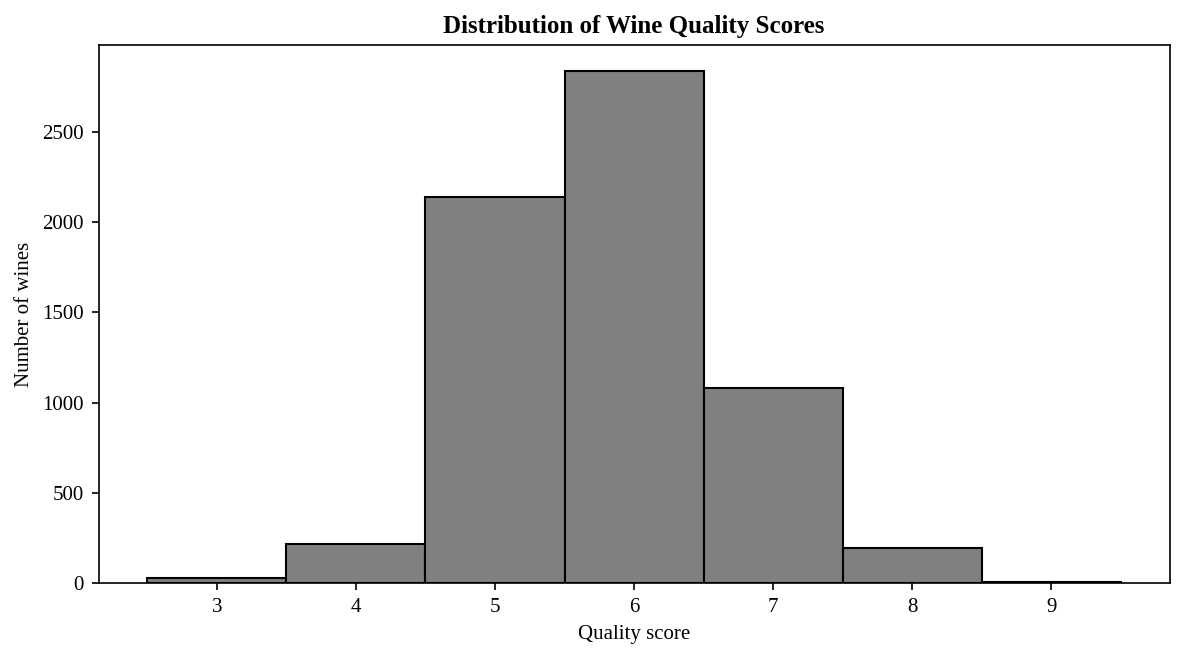

In [30]:
print(wine["quality"].value_counts().sort_index())
plt.figure(figsize=(8, 4.5))
plt.hist(wine["quality"], bins=np.arange(2.5, 10.5, 1), color="gray", edgecolor="black")
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality score")
plt.ylabel("Number of wines")
plt.xticks(range(3, 10))
plt.tight_layout()
plt.show()

#### Box Plot of Alcohol by Quality

         count  median   mean
quality                      
3           30   10.15  10.22
4          216   10.00  10.18
5         2138    9.60   9.84
6         2836   10.50  10.59
7         1079   11.40  11.39
8          193   12.00  11.68
9            5   12.50  12.18


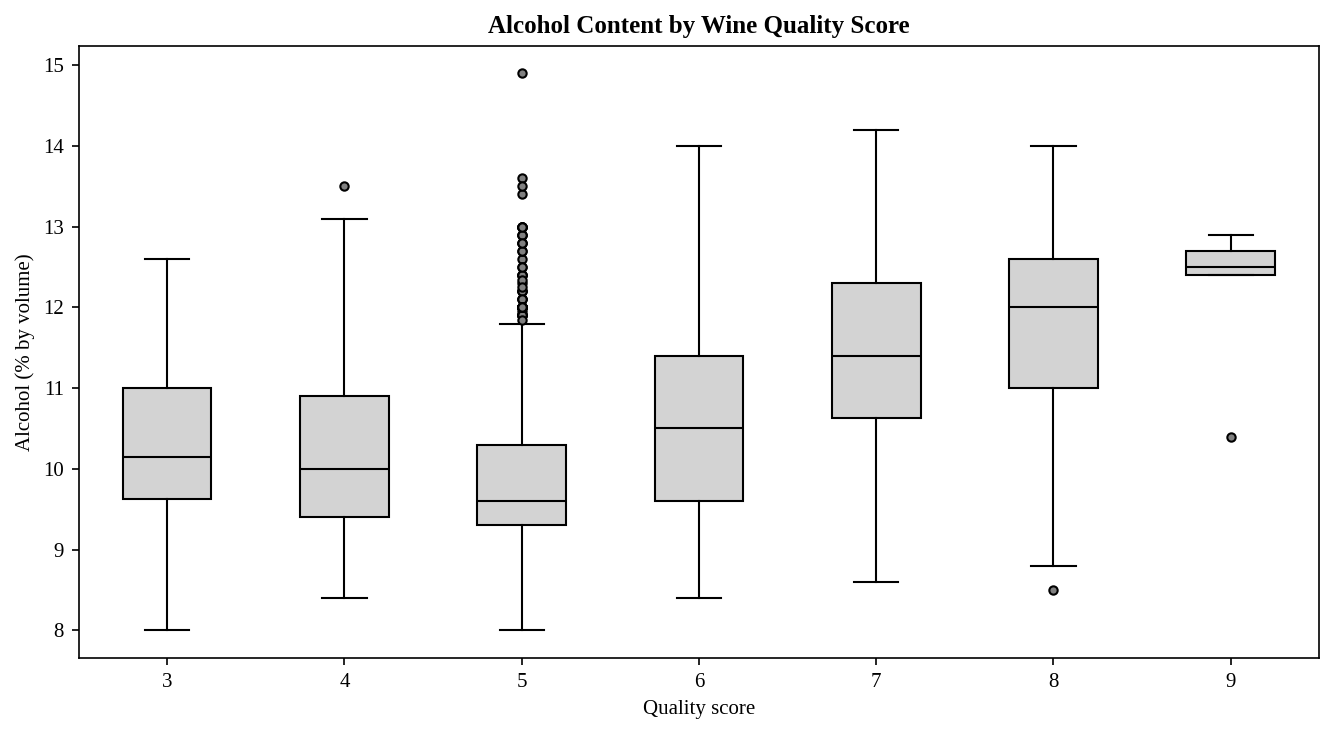

In [31]:
levels = sorted(wine["quality"].unique())
groups = [wine.loc[wine["quality"] == q, "alcohol"] for q in levels]
plt.figure(figsize=(9, 5))
plt.boxplot(groups, patch_artist=True,
            boxprops=dict(facecolor="lightgray", edgecolor="black"),
            medianprops=dict(color="black"),
            flierprops=dict(marker="o", markerfacecolor="gray", markeredgecolor="black", markersize=4))
plt.xticks(range(1, len(levels) + 1), levels)
plt.title("Alcohol Content by Wine Quality Score")
plt.xlabel("Quality score")
plt.ylabel("Alcohol (% by volume)")
plt.tight_layout()
plt.show()
print(wine.groupby("quality")["alcohol"].agg(["count", "median", "mean"]).round(2))

#### Correlation Heatmap

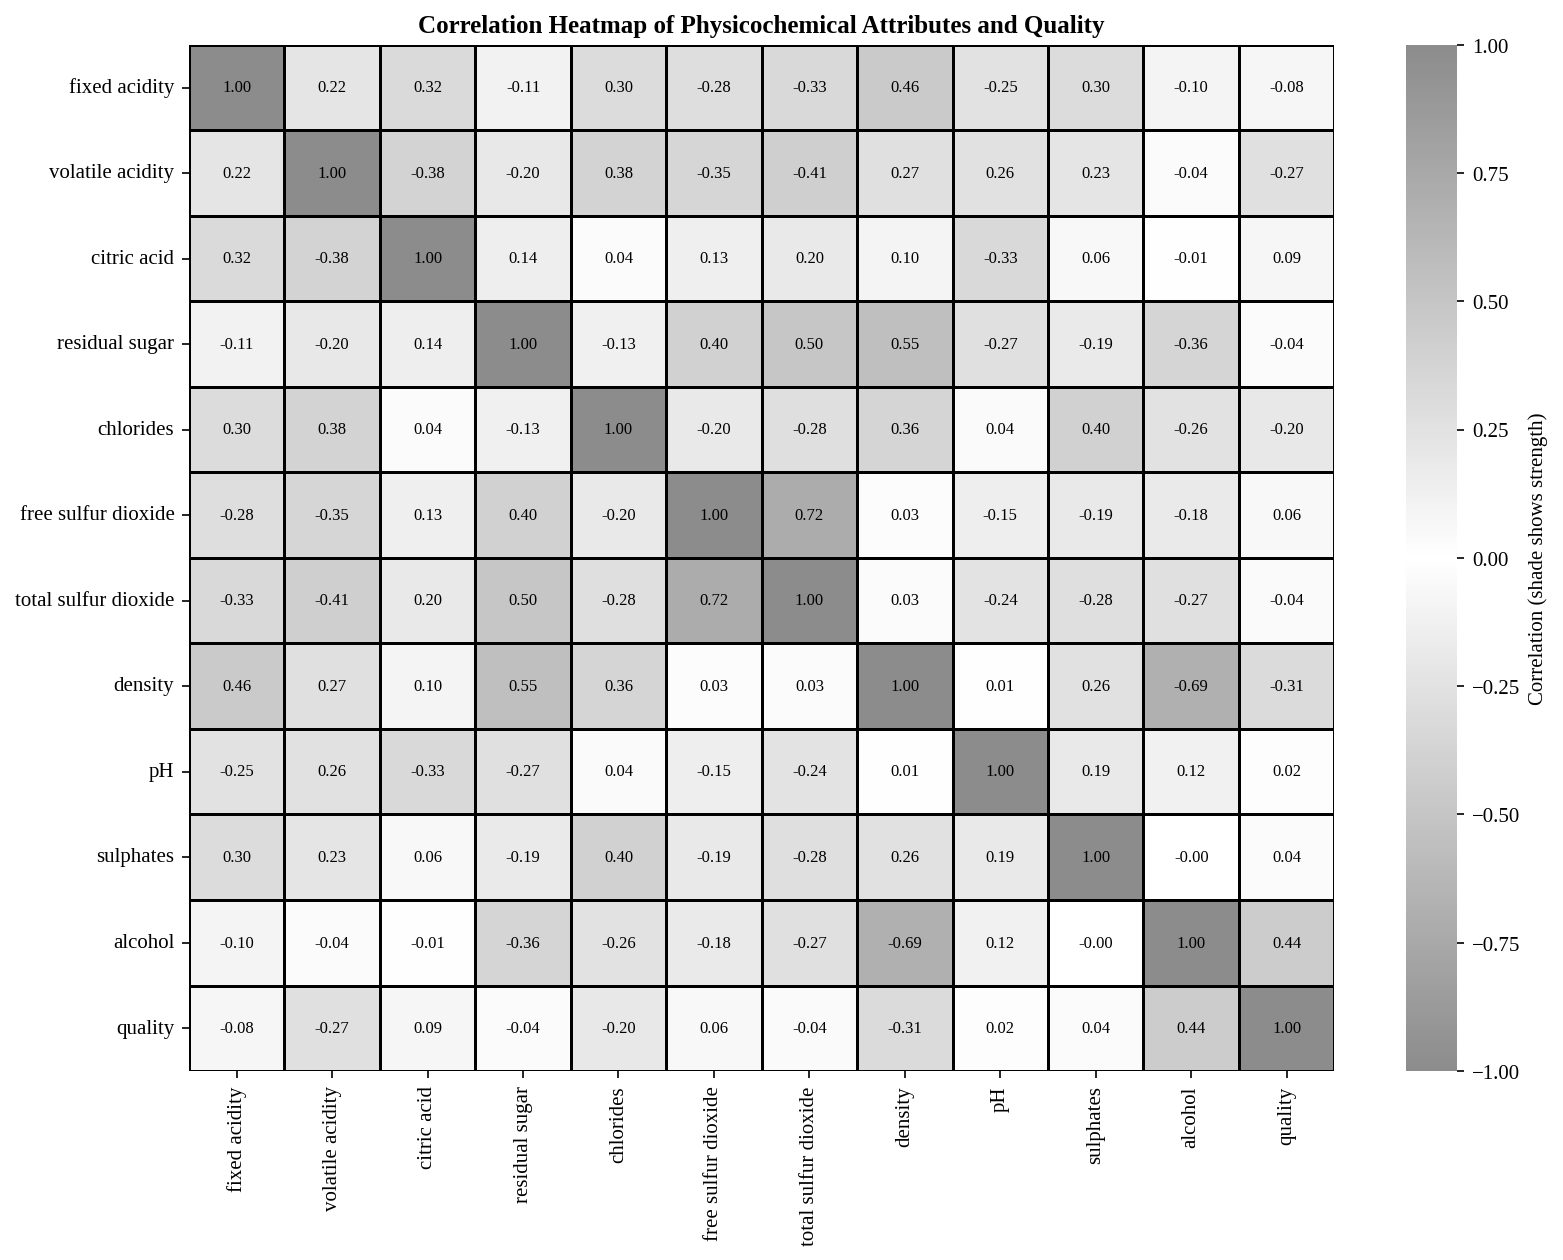

In [32]:
corr_wine = wine.corr()
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr_wine, annot=True, fmt=".2f", cmap=strength_map, vmin=-1, vmax=1,
            linewidths=0.5, linecolor="black", cbar_kws={"label": "Correlation (shade shows strength)"},
            annot_kws={"color": "black", "size": 8})
plt.title("Correlation Heatmap of Physicochemical Attributes and Quality")
plt.tight_layout()
plt.show()

#### Attributes Most Associated with Quality

In [33]:
quality_corr = corr_wine["quality"].drop("quality")
ranked = quality_corr.reindex(quality_corr.abs().sort_values(ascending=False).index)
print(ranked.round(4))

alcohol                 0.4443
density                -0.3059
volatile acidity       -0.2657
chlorides              -0.2007
citric acid             0.0855
fixed acidity          -0.0767
free sulfur dioxide     0.0555
total sulfur dioxide   -0.0414
sulphates               0.0385
residual sugar         -0.0370
pH                      0.0195
Name: quality, dtype: float64


### Task 3: Predictive Modelling

#### Train-Test Split and Model Training

In [34]:
X = wine.drop(columns="quality")
y = wine["quality"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

lin_reg = LinearRegression().fit(X_train, y_train)
y_pred = lin_reg.predict(X_test)

Training rows: 5197
Testing rows: 1300


#### Test Set Metrics

In [35]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("MAE :", round(mae, 4))
print("MSE :", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2  :", round(r2, 4))

errors = np.abs(y_test - y_pred)
print("Predictions within 0.5 of actual:", round((errors <= 0.5).mean() * 100, 1), "%")
print("Predictions within 1.0 of actual:", round((errors <= 1.0).mean() * 100, 1), "%")
print("Predicted range:", round(y_pred.min(), 2), "to", round(y_pred.max(), 2))

MAE : 0.5659
MSE : 0.5467
RMSE: 0.7394
R2  : 0.2598
Predictions within 0.5 of actual: 53.9 %
Predictions within 1.0 of actual: 84.2 %
Predicted range: 4.05 to 7.72


#### Standardised Coefficients

                      Raw coefficient  Standardised coefficient
alcohol                        0.2707                    0.3678
residual sugar                 0.0459                    0.2514
volatile acidity              -1.3508                   -0.2499
density                      -58.9451                   -0.2023
total sulfur dioxide          -0.0027                   -0.1706
free sulfur dioxide            0.0070                    0.1398
sulphates                      0.8084                    0.1371
fixed acidity                  0.0790                    0.1161
pH                             0.4828                    0.0879
citric acid                   -0.1438                   -0.0237
chlorides                     -0.3328                   -0.0132


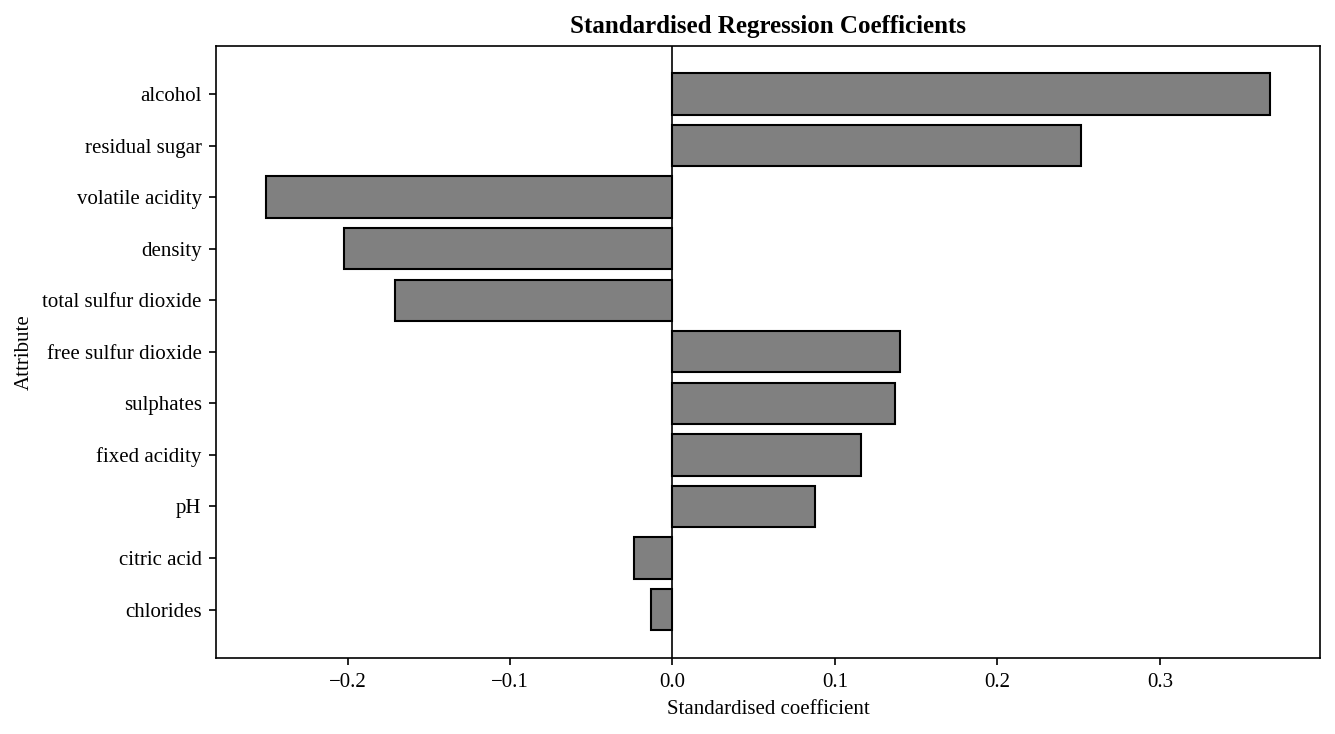

In [36]:
std_coef = pd.Series(lin_reg.coef_ * X_train.std().values / y_train.std(), index=X.columns)
std_coef_sorted = std_coef.reindex(std_coef.abs().sort_values(ascending=False).index)
print(pd.DataFrame({"Raw coefficient": pd.Series(lin_reg.coef_, index=X.columns).round(4),
                    "Standardised coefficient": std_coef.round(4)}).loc[std_coef_sorted.index])

plt.figure(figsize=(9, 5))
plt.barh(std_coef_sorted.index[::-1], std_coef_sorted.values[::-1], color="gray", edgecolor="black")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Standardised Regression Coefficients")
plt.xlabel("Standardised coefficient")
plt.ylabel("Attribute")
plt.tight_layout()
plt.show()

#### Multicollinearity Check Using VIF

In [37]:
vif_values = {}
for col in X_train.columns:
    others = X_train.drop(columns=col)
    r2_col = LinearRegression().fit(others, X_train[col]).score(others, X_train[col])
    vif_values[col] = 1 / (1 - r2_col)
vif = pd.Series(vif_values).sort_values(ascending=False)
print(vif.round(2))

density                 15.51
residual sugar           7.20
fixed acidity            4.74
alcohol                  4.62
total sulfur dioxide     2.96
pH                       2.47
free sulfur dioxide      2.16
volatile acidity         1.94
chlorides                1.65
citric acid              1.61
sulphates                1.54
dtype: float64


#### Predicted vs Actual Quality

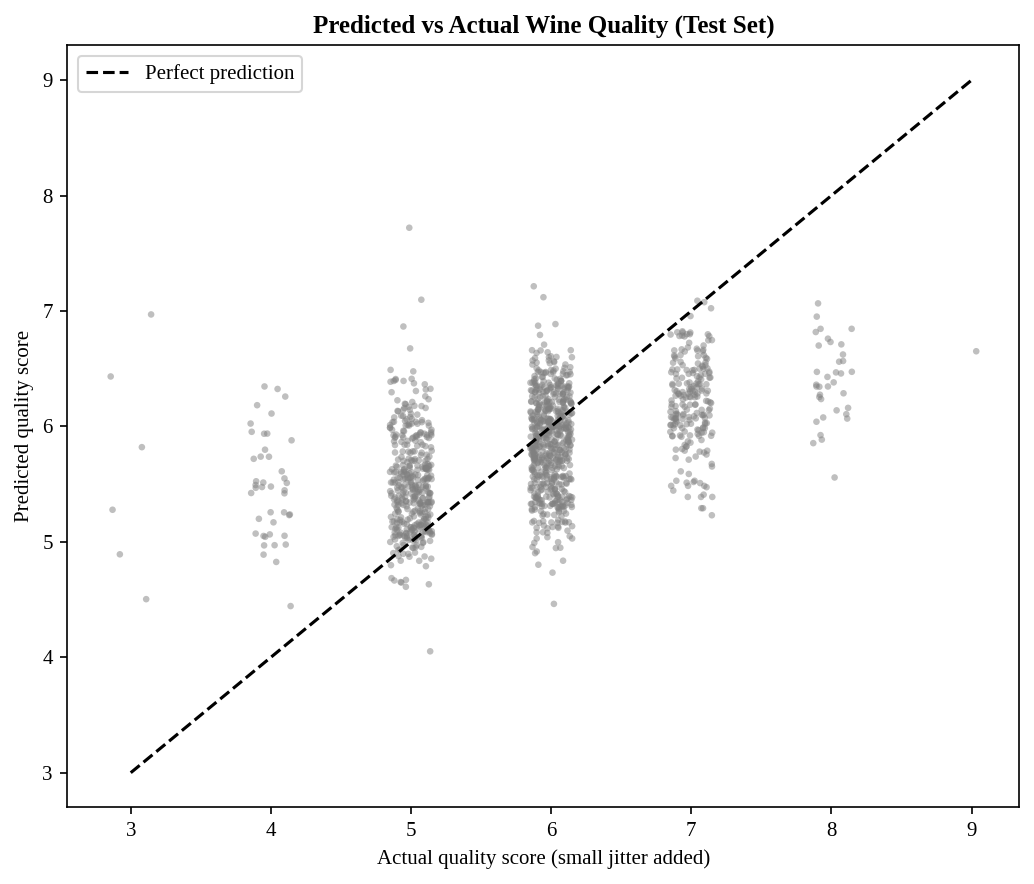

In [38]:
plt.figure(figsize=(7, 6))
rng = np.random.default_rng(42)
jitter = rng.uniform(-0.15, 0.15, size=len(y_test))
plt.scatter(y_test + jitter, y_pred, s=10, color="gray", alpha=0.5, edgecolor="none")
plt.plot([3, 9], [3, 9], color="black", linestyle="--", label="Perfect prediction")
plt.title("Predicted vs Actual Wine Quality (Test Set)")
plt.xlabel("Actual quality score (small jitter added)")
plt.ylabel("Predicted quality score")
plt.legend()
plt.tight_layout()
plt.show()

#### Model Comparison for Red and White Wine

In [39]:
rows = []
for name, data in [("Red", red), ("White", white), ("Combined", wine)]:
    Xs = data.drop(columns="quality")
    ys = data["quality"]
    Xa, Xb, ya, yb = train_test_split(Xs, ys, test_size=0.2, random_state=42)
    pred = LinearRegression().fit(Xa, ya).predict(Xb)
    rows.append([name, len(data), round(mean_absolute_error(yb, pred), 3),
                 round(np.sqrt(mean_squared_error(yb, pred)), 3), round(r2_score(yb, pred), 3)])
print(pd.DataFrame(rows, columns=["Dataset", "Rows", "MAE", "RMSE", "R2"]))

    Dataset  Rows    MAE   RMSE     R2
0       Red  1599  0.504  0.625  0.403
1     White  4898  0.586  0.754  0.265
2  Combined  6497  0.566  0.739  0.260
